In [1]:
!pip install xgboost -q

from sklearn.datasets import fetch_california_housing
df = fetch_california_housing(as_frame=True).frame
df.to_csv("housing.csv", index=False)

print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


            Model    MAE    MSE   RMSE     R2
          XGBoost 0.3107 0.2176 0.4665 0.8339
    Random Forest 0.3275 0.2554 0.5053 0.8051
   Neural Network 0.3505 0.2743 0.5237 0.7907
    Decision Tree 0.4482 0.4220 0.6497 0.6779
              KNN 0.4462 0.4324 0.6576 0.6700
Linear Regression 0.5332 0.5559 0.7456 0.5758


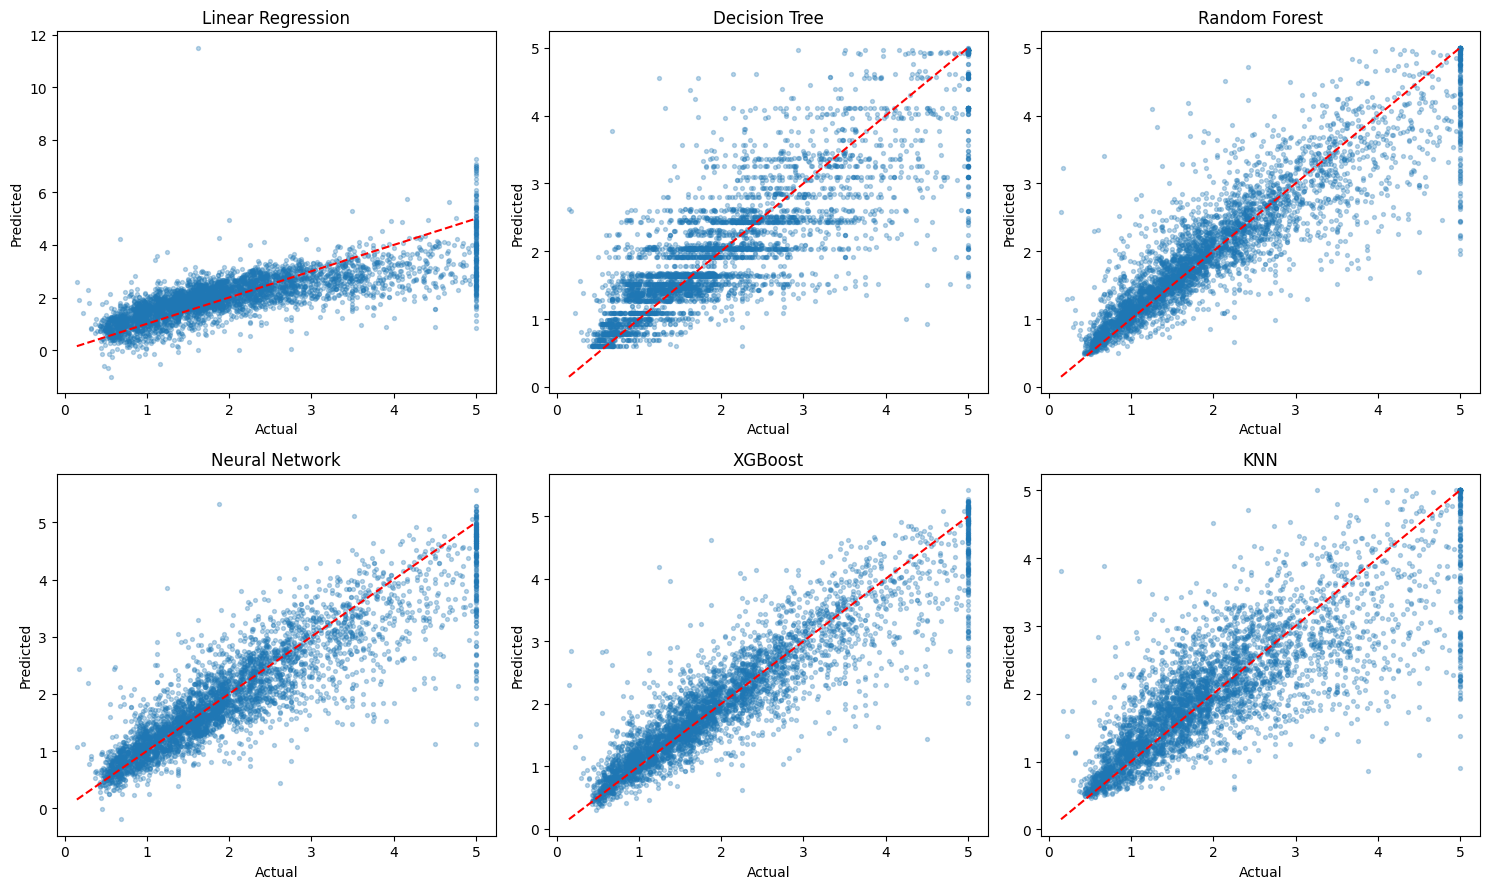

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Neural Network": make_pipeline(StandardScaler(),
        MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)),
    "XGBoost": XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42),
    "KNN": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
}

results, preds = [], {}
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    preds[name] = p
    mse = mean_squared_error(y_test, p)
    results.append([name, mean_absolute_error(y_test, p), mse, np.sqrt(mse), r2_score(y_test, p)])

table = pd.DataFrame(results, columns=["Model", "MAE", "MSE", "RMSE", "R2"]).sort_values("R2", ascending=False).round(4)
print(table.to_string(index=False))
table.to_csv("results.csv", index=False)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, p) in zip(axes.ravel(), preds.items()):
    ax.scatter(y_test, p, alpha=0.3, s=8)
    ax.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
    ax.set_title(name); ax.set_xlabel("Actual"); ax.set_ylabel("Predicted")
plt.tight_layout(); plt.savefig("actual_vs_predicted.png", dpi=150); plt.show()

In [3]:
print(df.isnull().sum())   # all zeros = no missing values
df.describe()


MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


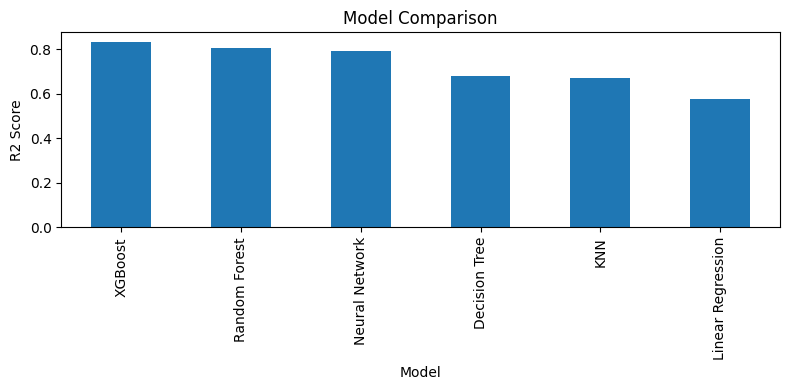

In [4]:
table.plot(x="Model", y="R2", kind="bar", legend=False, figsize=(8,4))
plt.ylabel("R2 Score"); plt.title("Model Comparison"); plt.tight_layout(); plt.show()

In this experiment, six regression algorithms (Linear Regression, Decision Tree, Random Forest, Neural Network, XGBoost and KNN) were applied to the California Housing dataset using the same features, the same target and the same 80:20 train/test split. Feature scaling was applied to Linear Regression, Neural Network and KNN. The models were evaluated using MAE, MSE, RMSE and R².

XGBoost was the best-performing algorithm. It had the lowest MAE (0.3107), MSE (0.2176) and RMSE (0.4665) and the highest R² score (0.8339), meaning it explains about 83% of the variation in house prices. XGBoost builds trees one after another, with each tree correcting the errors of the previous ones, and it uses regularization to avoid overfitting. This helps it capture the non-linear relationships between income, location and house value.

Random Forest was second (R² = 0.8051), followed by the Neural Network (R² = 0.7907). The Decision Tree (R² = 0.6779) and KNN (R² = 0.6700) gave average results. Linear Regression performed worst (R² = 0.5758) because house prices do not follow a purely linear relationship with the input features.

Therefore, ensemble methods performed best on this dataset, and XGBoost is the most suitable model for house price prediction in this experiment.